In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 25.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [ ]:
from pathlib import Path
import json, shutil, time, os
import numpy as np, pandas as pd, torch, cv2
from PIL import Image
from scipy import stats
import ultralytics
from ultralytics import YOLO

print("Ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| CUDA", torch.cuda.is_available())

DATASET_ROOT = Path("/kaggle/input/datasets/modigarinarendra/construction-site-sequence-safe/Private_UAV_Sequence_Safe")
OUT   = Path("/kaggle/working/UAV_v2")
YOLO_ROOT = OUT / "yolo_dataset"
RUNS  = OUT / "runs"
REPORTS = OUT / "reports"
for d in (OUT, RUNS, REPORTS): d.mkdir(parents=True, exist_ok=True)

# ---- protocol (identical for every model) ----
IMGSZ = 1280          # try 960 first if time is short
BATCH = 8             # drop to 4 if CUDA OOM
EPOCHS = 100
SEEDS = [42, 123, 2026]
TRAIN_KW = dict(
    imgsz=IMGSZ, batch=BATCH, epochs=EPOCHS,
    optimizer="AdamW", lr0=0.001, lrf=0.01, weight_decay=0.0005, cos_lr=True, warmup_epochs=3,
    scale=0.2, mosaic=1.0, close_mosaic=15,
    fliplr=0.5, flipud=0.0, degrees=0.0,      # upright people in oblique UAV view
    max_det=1000, workers=2, amp=True, deterministic=True, device=0, plots=False,
)
MODELS = {"YOLOv8n":"yolov8n.pt", "YOLOv9t":"yolov9t.pt", "YOLOv10n":"yolov10n.pt", "YOLO11n":"yolo11n.pt"}

In [ ]:
IMG_EXT = {".jpg",".jpeg",".png",".bmp",".tif",".tiff",".webp"}

if YOLO_ROOT.exists(): shutil.rmtree(YOLO_ROOT)
counts = {}
for split in ["train","val","test"]:
    (YOLO_ROOT/"images"/split).mkdir(parents=True)
    (YOLO_ROOT/"labels"/split).mkdir(parents=True)
    src = DATASET_ROOT/"images"/split
    n = 0
    for img in sorted(src.iterdir()):
        if img.suffix.lower() not in IMG_EXT: continue
        lab = DATASET_ROOT/"labels"/split/(img.stem + ".txt")
        if not lab.exists(): continue
        shutil.copy2(img, YOLO_ROOT/"images"/split/img.name)
        shutil.copy2(lab, YOLO_ROOT/"labels"/split/lab.name)
        n += 1
    counts[split] = n
print("images per split:", counts)

# filename-stem overlap check between splits (frames from one video can leak across splits)
stems = {s: {p.stem for p in (YOLO_ROOT/"images"/s).iterdir()} for s in counts}
for a,b in [("train","val"),("train","test"),("val","test")]:
    print(f"identical filenames {a}/{b}:", len(stems[a] & stems[b]))

DATA_YAML = YOLO_ROOT/"data.yaml"
DATA_YAML.write_text(f"path: {YOLO_ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 1\nnames: ['person']\n")
print(DATA_YAML.read_text())

In [ ]:
W, H = Image.open(next((YOLO_ROOT/"images"/"train").iterdir())).size
print("image size:", (W, H))
for split in ["train","val","test"]:
    ws, hs = [], []
    for f in (YOLO_ROOT/"labels"/split).glob("*.txt"):
        for l in f.read_text().splitlines():
            p = l.split()
            if len(p) == 5: ws.append(float(p[3])*W); hs.append(float(p[4])*H)
    ws, hs = np.array(ws), np.array(hs)
    a = np.sqrt(ws*hs)
    print(f"{split:5s} n={len(ws):5d} median w,h = {np.median(ws):.1f},{np.median(hs):.1f}px | sqrt(area)<16: {(a<16).mean()*100:.1f}% | <32: {(a<32).mean()*100:.1f}%")

In [ ]:
def run_dir(name, seed): return RUNS/f"{name}_seed{seed}"
def best_pt(name, seed): return run_dir(name, seed)/"weights"/"best.pt"

def train_one(name, init, seed, weights=None):
    if best_pt(name, seed).exists():
        print("[skip]", name, seed); return
    print("="*70, f"\nTRAINING {name} seed={seed}\n" + "="*70)
    model = YOLO(init)
    if weights: model = model.load(weights)      # for P2 yaml + pretrained transfer
    model.train(data=str(DATA_YAML), seed=seed, project=str(RUNS), name=f"{name}_seed{seed}",
                exist_ok=True, pretrained=True, **TRAIN_KW)

for seed in SEEDS:
    for name, w in MODELS.items():
        try:
            train_one(name, w, seed)
        except torch.cuda.OutOfMemoryError:
            print(f"OOM for {name}; lower BATCH or IMGSZ and re-run this cell.")
            torch.cuda.empty_cache(); raise
        torch.cuda.empty_cache()

In [ ]:
cfg_dir = Path(ultralytics.__file__).parent/"cfg/models"
print("P2 configs available:", sorted(p.relative_to(cfg_dir).as_posix() for p in cfg_dir.rglob("*p2*.yaml")))

RUN_P2 = False   # set True to run
P2 = {"YOLOv8n-P2": ("yolov8n-p2.yaml","yolov8n.pt"),
      "YOLO11n-P2": ("yolo11n-p2.yaml","yolo11n.pt")}
if RUN_P2:
    for seed in SEEDS:
        for name,(yaml_,w) in P2.items():
            train_one(name, yaml_, seed, weights=w)
            torch.cuda.empty_cache()

In [ ]:
ALL = list(MODELS) + [n for n in ("YOLOv8n-P2","YOLO11n-P2") if any(best_pt(n,s).exists() for s in SEEDS)]
rows = []
for seed in SEEDS:
    for name in ALL:
        pt = best_pt(name, seed)
        if not pt.exists(): continue
        m = YOLO(str(pt))
        res = {}
        for split in ["val","test"]:
            r = m.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, conf=0.001, iou=0.6,
                      max_det=1000, workers=2, plots=False, verbose=False, device=0)
            b = r.box
            res[split] = dict(P=float(b.mp), R=float(b.mr), mAP50=float(b.map50), mAP50_95=float(b.map))
        rows.append({"model":name, "seed":seed,
                     **{f"test_{k}":v for k,v in res["test"].items()},
                     **{f"val_{k}":v for k,v in res["val"].items()}})
eval_df = pd.DataFrame(rows)
eval_df.to_csv(REPORTS/"metrics_by_seed.csv", index=False)
print(eval_df.round(4).to_string(index=False))

In [ ]:
METRICS = ["test_P","test_R","test_mAP50","test_mAP50_95"]
def ci95(x):
    x = np.asarray(x, float); n = len(x); mu = x.mean()
    if n < 2: return mu, np.nan, np.nan, np.nan
    sd = x.std(ddof=1); h = stats.t.ppf(.975, n-1)*sd/np.sqrt(n)
    return mu, sd, mu-h, mu+h

summ = []
for name, g in eval_df.groupby("model", sort=False):
    row = {"model":name, "n_seeds":len(g)}
    for m in METRICS:
        mu, sd, lo, hi = ci95(g[m]); row.update({f"{m}_mean":mu, f"{m}_sd":sd, f"{m}_lo":lo, f"{m}_hi":hi})
    summ.append(row)
summary_df = pd.DataFrame(summ)
summary_df.to_csv(REPORTS/"summary_mean_sd_ci.csv", index=False)
for _, r in summary_df.iterrows():
    print(r.model, " | ".join(f"{m[5:]}: {r[m+'_mean']:.3f}±{r[m+'_sd']:.3f}" for m in METRICS))

pairs, names = [], list(eval_df.model.unique())
for i in range(len(names)):
    for j in range(i+1, len(names)):
        a, b = names[i], names[j]
        da = eval_df[eval_df.model==a].set_index("seed"); db = eval_df[eval_df.model==b].set_index("seed")
        common = sorted(set(da.index) & set(db.index))
        for m in METRICS:
            x, y = da.loc[common, m].to_numpy(), db.loc[common, m].to_numpy()
            if len(common) >= 2:
                t, p = stats.ttest_rel(x, y)
            else: t = p = np.nan
            pairs.append(dict(A=a, B=b, metric=m, n=len(common), mean_diff=(x-y).mean() if len(common) else np.nan, t=t, p=p))
paired_df = pd.DataFrame(pairs); paired_df.to_csv(REPORTS/"paired_comparisons.csv", index=False)
print(paired_df.round(4).to_string(index=False))

In [ ]:
from ultralytics.utils.torch_utils import get_flops
img = cv2.imread(str(next((YOLO_ROOT/"images"/"test").iterdir())))
eff = []
for name in ALL:
    pt = best_pt(name, SEEDS[0])
    if not pt.exists(): continue
    m = YOLO(str(pt))
    params = sum(p.numel() for p in m.model.parameters())
    try: gf = float(get_flops(m.model, imgsz=IMGSZ))
    except Exception as e: gf = np.nan
    for _ in range(20): m.predict(img, imgsz=IMGSZ, conf=0.25, verbose=False, device=0)
    torch.cuda.synchronize(); t = []
    for _ in range(100):
        t0 = time.perf_counter()
        m.predict(img, imgsz=IMGSZ, conf=0.25, verbose=False, device=0)
        torch.cuda.synchronize(); t.append((time.perf_counter()-t0)*1000)
    t = np.array(t)
    eff.append(dict(model=name, params_M=params/1e6, GFLOPs_at_imgsz=gf, ckpt_MB=pt.stat().st_size/2**20,
                    latency_ms_mean=t.mean(), latency_ms_sd=t.std(ddof=1), p95=np.percentile(t,95),
                    note=f"end-to-end predict() on a preloaded array, bs=1, imgsz={IMGSZ}, {torch.cuda.get_device_name(0)}"))
eff_df = pd.DataFrame(eff); eff_df.to_csv(REPORTS/"efficiency.csv", index=False)
print(eff_df.drop(columns="note").round(3).to_string(index=False))

master = summary_df.merge(eff_df.drop(columns="note"), on="model", how="left")
master.to_csv(REPORTS/"MASTER_table.csv", index=False)
print("\nSaved all reports to", REPORTS)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
runs found: ['YOLO11n_seed123', 'YOLO11n_seed2026', 'YOLO11n_seed42', 'YOLOv10n_seed123', 'YOLOv10n_seed2026', 'YOLOv10n_seed42', 'YOLOv8n_seed123', 'YOLOv8n_seed2026', 'YOLOv8n_seed42', 'YOLOv9t_seed123', 'YOLOv9t_seed2026', 'YOLOv9t_seed42']
   model  seed  TP  FP  FN  precision  recall
 YOLOv8n    42 409 502 162      0.449   0.716
 YOLOv8n   123 368 251 203      0.595   0.644
 YOLOv8n  2026 401 418 170      0.490   0.702
 YOLOv9t    42 388 281 183      0.580   0.680
 YOLOv9t   123 382 281 189      0.576   0.669
 YOLOv9t  2026 369 246 202      0.600   0.646
YOLOv10n    42 339 214 232      0.613   0.594
YOLOv10n   123 418 459 153      0.477   0.732
YOLOv10n  2026 330 163 241      0.669   0.578
 YOL

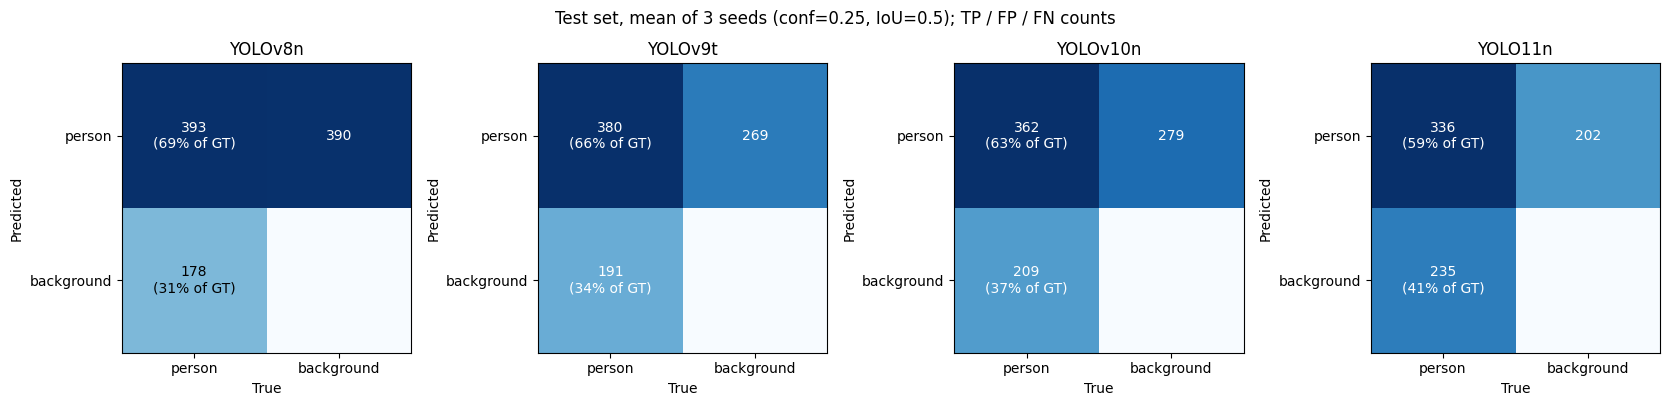

In [2]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ultralytics import YOLO

# READ-ONLY input (your saved experiment)
SRC       = Path("/kaggle/input/datasets/modigarinarendra/yolo-4-models-output-from-claide-code/UAV_v2")
YOLO_ROOT = SRC/"yolo_dataset"
RUNS      = SRC/"runs"

# WRITABLE output
OUT = Path("/kaggle/working/UAV_v2")
(OUT/"reports").mkdir(parents=True, exist_ok=True)

IMGSZ     = 1280                     # same as training
CONF, IOU_MATCH = 0.25, 0.5          # operating point for the matrix
MODELS    = ["YOLOv8n", "YOLOv9t", "YOLOv10n", "YOLO11n"]
SEEDS     = [42, 123, 2026]

print("runs found:", sorted(p.name for p in RUNS.glob("*"))[:12])

def iou_mat(a, b):                   # a: (N,4) b: (M,4) xyxy
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    tl = np.maximum(a[:,None,:2], b[None,:,:2]); br = np.minimum(a[:,None,2:], b[None,:,2:])
    inter = np.clip(br - tl, 0, None).prod(2)
    area = lambda x: (x[:,2]-x[:,0])*(x[:,3]-x[:,1])
    return inter / (area(a)[:,None] + area(b)[None] - inter + 1e-9)

def load_gt(lab, w, h):
    rows = [list(map(float, l.split()[1:5])) for l in lab.read_text().splitlines() if len(l.split()) >= 5]
    if not rows: return np.zeros((0,4))
    r = np.array(rows) * [w, h, w, h]
    return np.c_[r[:,0]-r[:,2]/2, r[:,1]-r[:,3]/2, r[:,0]+r[:,2]/2, r[:,1]+r[:,3]/2]

def count(model, split="test"):
    TP = FP = FN = 0
    for img in sorted((YOLO_ROOT/"images"/split).iterdir()):
        res = model.predict(str(img), imgsz=IMGSZ, conf=CONF, iou=0.6, max_det=1000, verbose=False, device=0)[0]
        h, w = res.orig_shape
        gt = load_gt(YOLO_ROOT/"labels"/split/(img.stem + ".txt"), w, h)
        order = np.argsort(-res.boxes.conf.cpu().numpy())
        pr = res.boxes.xyxy.cpu().numpy()[order]
        M = iou_mat(pr, gt); used = set(); tp = 0
        for i in range(len(pr)):                         # greedy match by confidence
            if M.shape[1] == 0: break
            j = int(np.argmax(np.where([k in used for k in range(M.shape[1])], -1, M[i])))
            if j not in used and M[i, j] >= IOU_MATCH: used.add(j); tp += 1
        TP += tp; FP += len(pr) - tp; FN += len(gt) - tp
    return TP, FP, FN

rows = []
for name in MODELS:
    for seed in SEEDS:
        pt = RUNS/f"{name}_seed{seed}"/"weights"/"best.pt"
        if pt.exists():
            tp, fp, fn = count(YOLO(str(pt)))
            rows.append(dict(model=name, seed=seed, TP=tp, FP=fp, FN=fn,
                             precision=tp/(tp+fp+1e-9), recall=tp/(tp+fn+1e-9)))
cm_df = pd.DataFrame(rows)
cm_df.to_csv(OUT/"reports"/"confusion_counts_by_seed.csv", index=False)   # now writes to /kaggle/working
print(cm_df.round(3).to_string(index=False))

# ---- draw: mean counts over seeds, 1 panel per model ----
mean = cm_df.groupby("model")[["TP","FP","FN"]].mean().reindex(MODELS)
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2*len(MODELS), 4))
for ax, name in zip(axes, MODELS):
    tp, fp, fn = mean.loc[name]
    mat = np.array([[tp, fp], [fn, np.nan]])             # rows: predicted person / background; cols: true person / background
    ax.imshow(np.nan_to_num(mat), cmap="Blues", vmin=0, vmax=max(tp, fp, fn))
    for (i, j), v in np.ndenumerate(mat):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}\n({v/(tp+fn)*100:.0f}% of GT)" if j == 0 else f"{v:.0f}",
                    ha="center", va="center", color="white" if v > max(tp, fp, fn)/2 else "black")
    ax.set_xticks([0, 1], ["person", "background"]); ax.set_yticks([0, 1], ["person", "background"])
    ax.set_xlabel("True"); ax.set_ylabel("Predicted"); ax.set_title(name)
fig.suptitle(f"Test set, mean of {len(SEEDS)} seeds (conf={CONF}, IoU={IOU_MATCH}); TP / FP / FN counts")
plt.tight_layout(); plt.savefig(OUT/"reports"/"confusion_matrices_counts.png", dpi=200); plt.show()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
available runs: {'YOLOv8n': [42, 123, 2026], 'YOLOv9t': [42, 123, 2026], 'YOLOv10n': [42, 123, 2026], 'YOLO11n': [42, 123, 2026]}
operating confidence per model (chosen on val): {'YOLOv8n': 0.3, 'YOLOv9t': 0.2, 'YOLOv10n': 0.2, 'YOLO11n': 0.1}
   Model  conf (val-selected)           TP            FP           FN     Precision        Recall            F1
 YOLOv8n                  0.3 382.0 ± 25.4 333.7 ± 104.0 189.0 ± 25.4 0.542 ± 0.067 0.669 ± 0.044 0.595 ± 0.022
 YOLOv9t                  0.2  395.3 ± 8.5  314.0 ± 14.7  175.7 ± 8.5 0.557 ± 0.009 0.692 ± 0.015 0.618 ± 0.007
YOLOv10n                  0.2 385.3 ± 44.1 334.0 ± 192.4 185.7 ± 44.1 0.559 ± 0.106 0.675 ± 0.077 0.602 ± 0.039
 YOLO11n        

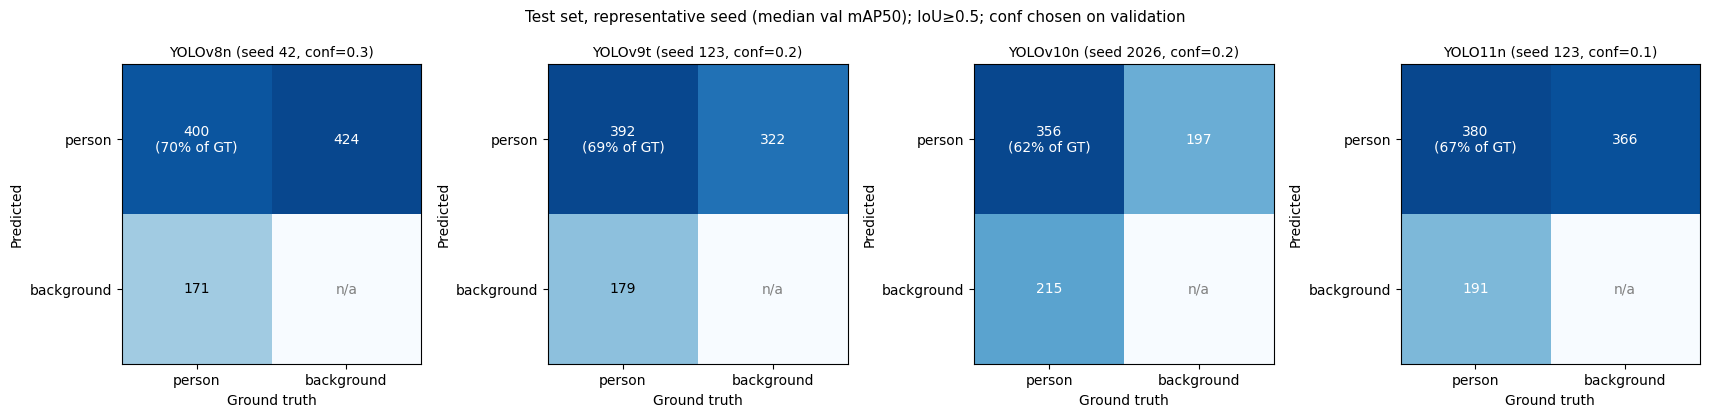

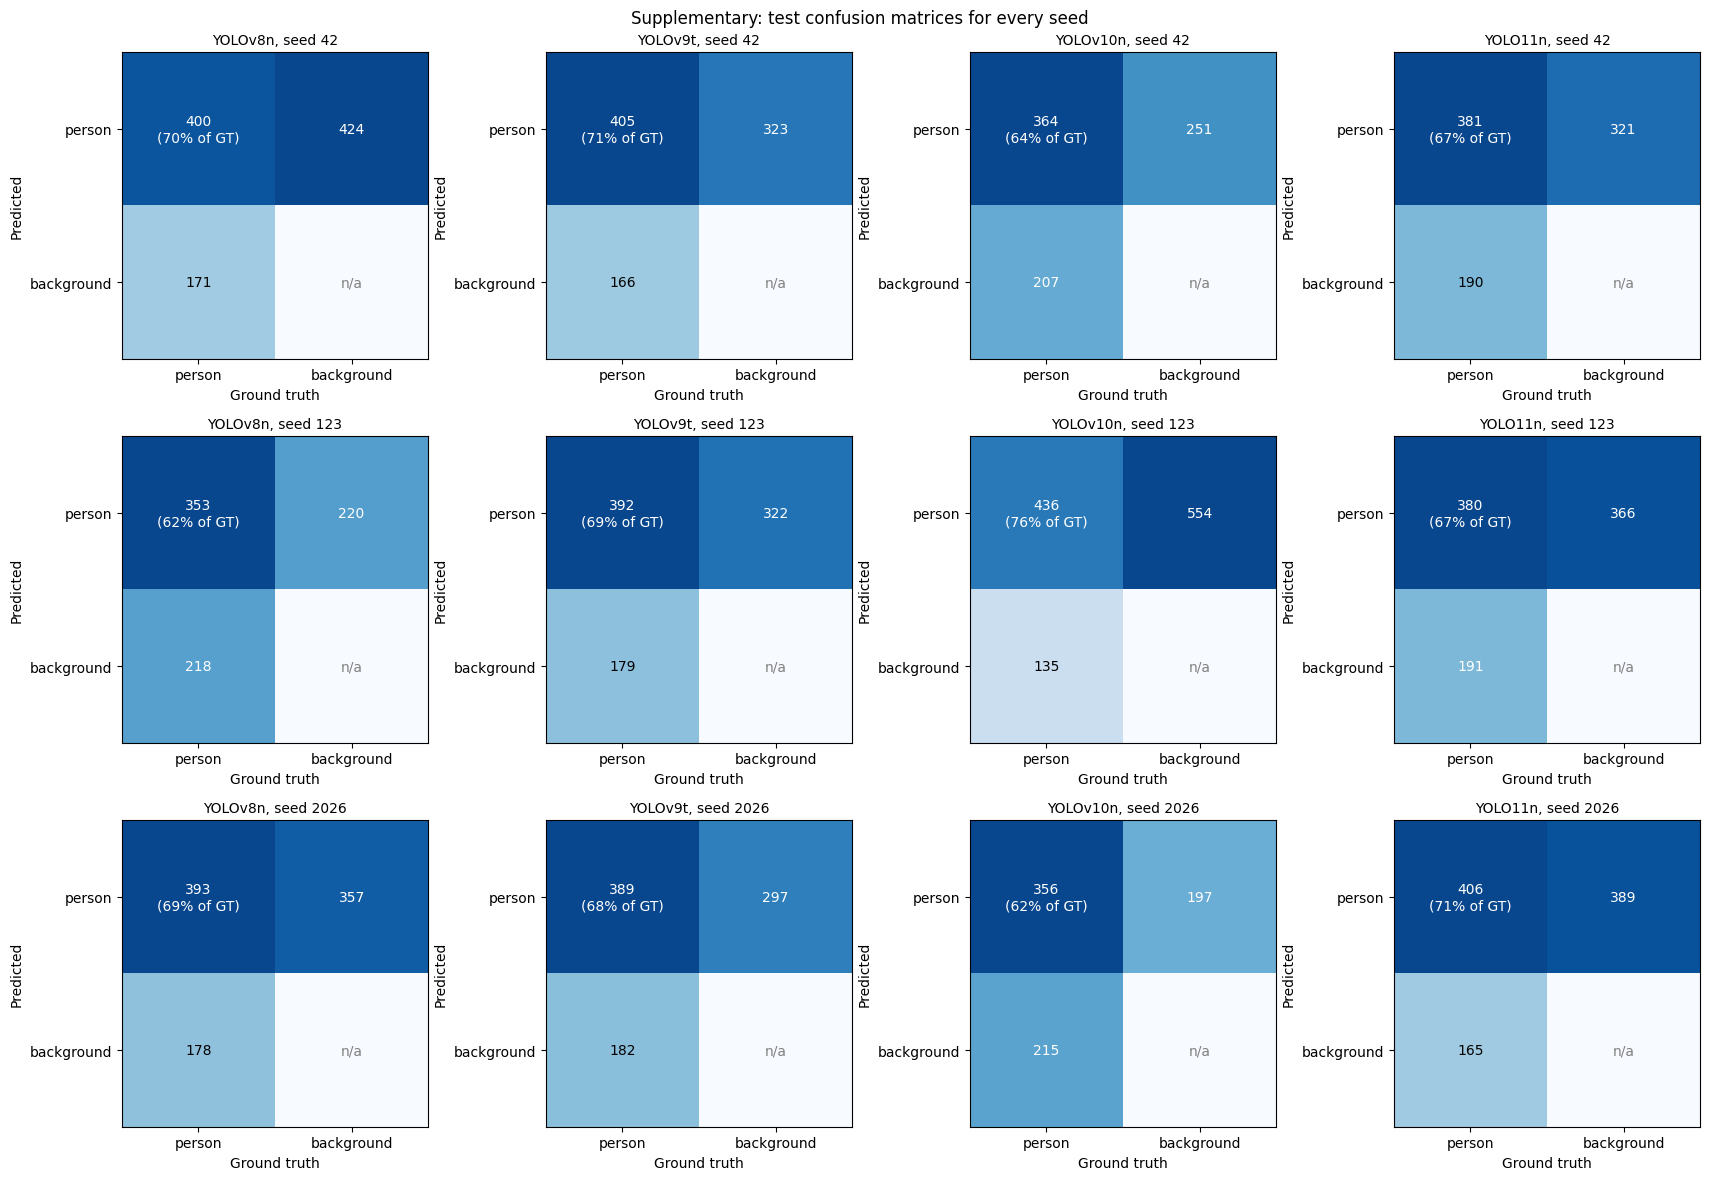

In [3]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ultralytics import YOLO

SRC       = Path("/kaggle/input/datasets/modigarinarendra/yolo-4-models-output-from-claide-code/UAV_v2")  # read-only
YOLO_ROOT = SRC/"yolo_dataset"
RUNS      = SRC/"runs"
OUT       = Path("/kaggle/working/UAV_v2"); (OUT/"reports").mkdir(parents=True, exist_ok=True)

IMGSZ, IOU_MATCH = 1280, 0.5
MODELS = ["YOLOv8n", "YOLOv9t", "YOLOv10n", "YOLO11n"]
SEEDS  = [42, 123, 2026]
CONF_GRID = np.round(np.arange(0.05, 0.80, 0.05), 2)

# ---------- helpers ----------
def iou_mat(a, b):
    tl = np.maximum(a[:,None,:2], b[None,:,:2]); br = np.minimum(a[:,None,2:], b[None,:,2:])
    inter = np.clip(br - tl, 0, None).prod(2)
    area = lambda x: (x[:,2]-x[:,0])*(x[:,3]-x[:,1])
    return inter / (area(a)[:,None] + area(b)[None] - inter + 1e-9)

def load_gt(lab, w, h):
    rows = [list(map(float, l.split()[1:5])) for l in lab.read_text().splitlines() if len(l.split()) >= 5]
    if not rows: return np.zeros((0,4))
    r = np.array(rows) * [w, h, w, h]
    return np.c_[r[:,0]-r[:,2]/2, r[:,1]-r[:,3]/2, r[:,0]+r[:,2]/2, r[:,1]+r[:,3]/2]

def n_matched(pr, gt):                                   # pr sorted by confidence, greedy 1-to-1 matching
    if len(pr) == 0 or len(gt) == 0: return 0
    M = iou_mat(pr, gt); used = np.zeros(len(gt), bool); tp = 0
    for i in range(len(pr)):
        m = np.where(used, -1, M[i]); j = int(m.argmax())
        if m[j] >= IOU_MATCH: used[j] = True; tp += 1
    return tp

# ---------- cache predictions once (low conf; thresholded later) ----------
cache = {}
def get_preds(name, seed, split):
    key = (name, seed, split)
    if key in cache: return cache[key]
    model = YOLO(str(RUNS/f"{name}_seed{seed}"/"weights"/"best.pt"))
    items = []
    for img in sorted((YOLO_ROOT/"images"/split).iterdir()):
        r = model.predict(str(img), imgsz=IMGSZ, conf=0.01, iou=0.6, max_det=1000, verbose=False, device=0)[0]
        h, w = r.orig_shape
        conf = r.boxes.conf.cpu().numpy(); o = np.argsort(-conf)
        items.append((r.boxes.xyxy.cpu().numpy()[o], conf[o],
                      load_gt(YOLO_ROOT/"labels"/split/(img.stem + ".txt"), w, h)))
    cache[key] = items
    return items

def counts_at(items, conf):
    TP = FP = FN = 0
    for boxes, confs, gt in items:
        pr = boxes[confs >= conf]
        tp = n_matched(pr, gt); TP += tp; FP += len(pr) - tp; FN += len(gt) - tp
    return TP, FP, FN

def prf(tp, fp, fn):
    p = tp/(tp+fp+1e-9); r = tp/(tp+fn+1e-9); return p, r, 2*p*r/(p+r+1e-9)

avail = {m: [s for s in SEEDS if (RUNS/f"{m}_seed{s}"/"weights"/"best.pt").exists()] for m in MODELS}
print("available runs:", avail)

# ---------- 1) operating point chosen on VALIDATION (max mean F1 over seeds) ----------
op, sweep = {}, []
for m in MODELS:
    f1s = []
    for c in CONF_GRID:
        f1s.append(np.mean([prf(*counts_at(get_preds(m, s, "val"), c))[2] for s in avail[m]]))
        sweep.append(dict(model=m, conf=c, val_F1=f1s[-1]))
    op[m] = float(CONF_GRID[int(np.argmax(f1s))])
pd.DataFrame(sweep).to_csv(OUT/"reports"/"val_conf_sweep.csv", index=False)
print("operating confidence per model (chosen on val):", op)

# ---------- 2) test counts per seed at that operating point ----------
rows = []
for m in MODELS:
    for s in avail[m]:
        tp, fp, fn = counts_at(get_preds(m, s, "test"), op[m]); p, r, f1 = prf(tp, fp, fn)
        rows.append(dict(model=m, seed=s, conf=op[m], TP=tp, FP=fp, FN=fn, precision=p, recall=r, F1=f1))
per_seed = pd.DataFrame(rows); per_seed.to_csv(OUT/"reports"/"test_counts_by_seed.csv", index=False)

# ---------- 3) mean ± SD table ----------
tab = []
for m, g in per_seed.groupby("model", sort=False):
    f = lambda c, d=1: f"{g[c].mean():.{d}f} ± {g[c].std(ddof=1):.{d}f}"
    tab.append({"Model": m, "conf (val-selected)": op[m], "TP": f("TP"), "FP": f("FP"), "FN": f("FN"),
                "Precision": f("precision", 3), "Recall": f("recall", 3), "F1": f("F1", 3)})
table = pd.DataFrame(tab); table.to_csv(OUT/"reports"/"test_confusion_table_mean_sd.csv", index=False)
print(table.to_string(index=False))

# ---------- 4) representative seed = median validation mAP50 (best epoch in results.csv) ----------
def val_map50(m, s):
    df = pd.read_csv(RUNS/f"{m}_seed{s}"/"results.csv"); df.columns = [c.strip() for c in df.columns]
    return df[[c for c in df.columns if c.startswith("metrics/mAP50(")][0]].max()
rep = {}
for m in MODELS:
    ranked = sorted(avail[m], key=lambda s: val_map50(m, s)); rep[m] = ranked[len(ranked)//2]
print("representative seed (median val mAP50):", rep)

# # ---------- 5) drawing ----------
# def draw(ax, tp, fp, fn, title):
#     vmax = max(tp, fp, fn, 1)
#     ax.imshow(np.array([[tp, fp], [fn, 0]]), cmap="Blues", vmin=0, vmax=vmax*1.1)
#     ax.text(0, 0, f"{tp}\\n({tp/(tp+fn)*100:.0f}% of GT)", ha="center", va="center", color="white" if tp > vmax/2 else "black")
#     ax.text(1, 0, f"{fp}", ha="center", va="center", color="white" if fp > vmax/2 else "black")
#     ax.text(0, 1, f"{fn}", ha="center", va="center", color="white" if fn > vmax/2 else "black")
#     ax.text(1, 1, "n/a", ha="center", va="center", color="gray")
#     ax.set_xticks([0, 1], ["person", "background"]); ax.set_yticks([0, 1], ["person", "background"])
#     ax.set_xlabel("Ground truth"); ax.set_ylabel("Predicted"); ax.set_title(title, fontsize=10)

# ---------- 5) drawing ----------
def draw(ax, tp, fp, fn, title):

    vmax = max(tp, fp, fn, 1)

    ax.imshow(
        np.array([[tp, fp], [fn, 0]]),
        cmap="Blues",
        vmin=0,
        vmax=vmax * 1.1
    )

    # TP: actual value + percentage on a NEW line
    ax.text(
        0, 0,
        f"{tp}\n({tp/(tp+fn)*100:.0f}% of GT)",
        ha="center",
        va="center",
        color="white" if tp > vmax/2 else "black"
    )

    # FP
    ax.text(
        1, 0,
        f"{fp}",
        ha="center",
        va="center",
        color="white" if fp > vmax/2 else "black"
    )

    # FN
    ax.text(
        0, 1,
        f"{fn}",
        ha="center",
        va="center",
        color="white" if fn > vmax/2 else "black"
    )

    # Background cell
    ax.text(
        1, 1,
        "n/a",
        ha="center",
        va="center",
        color="gray"
    )

    ax.set_xticks(
        [0, 1],
        ["person", "background"]
    )

    ax.set_yticks(
        [0, 1],
        ["person", "background"]
    )

    ax.set_xlabel("Ground truth")
    ax.set_ylabel("Predicted")

    ax.set_title(
        title,
        fontsize=10
    )
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.3*len(MODELS), 4.2))
for ax, m in zip(axes, MODELS):
    r = per_seed[(per_seed.model == m) & (per_seed.seed == rep[m])].iloc[0]
    draw(ax, int(r.TP), int(r.FP), int(r.FN), f"{m} (seed {rep[m]}, conf={op[m]})")
fig.suptitle(f"Test set, representative seed (median val mAP50); IoU≥{IOU_MATCH}; conf chosen on validation", fontsize=11)
plt.tight_layout(); plt.savefig(OUT/"reports"/"confusion_matrices_representative_seed.png", dpi=250); plt.show()

fig, axes = plt.subplots(len(SEEDS), len(MODELS), figsize=(4.3*len(MODELS), 4.0*len(SEEDS)))
for i, s in enumerate(SEEDS):
    for j, m in enumerate(MODELS):
        ax = axes[i, j]; r = per_seed[(per_seed.model == m) & (per_seed.seed == s)]
        if len(r): r = r.iloc[0]; draw(ax, int(r.TP), int(r.FP), int(r.FN), f"{m}, seed {s}")
        else: ax.axis("off")
fig.suptitle("Supplementary: test confusion matrices for every seed", fontsize=12)
plt.tight_layout(); plt.savefig(OUT/"reports"/"confusion_matrices_all_seeds.png", dpi=200); plt.show()

PATH CHECK
SRC       : /kaggle/input/datasets/modigarinarendra/yolo-4-models-output-from-claide-code/UAV_v2
YOLO_ROOT : /kaggle/input/datasets/modigarinarendra/yolo-4-models-output-from-claide-code/UAV_v2/yolo_dataset
RUNS      : /kaggle/input/datasets/modigarinarendra/yolo-4-models-output-from-claide-code/UAV_v2/runs
OUT       : /kaggle/working/UAV_v2
REPORTS   : /kaggle/working/UAV_v2/reports

Available run directories:
  YOLO11n_seed123
  YOLO11n_seed2026
  YOLO11n_seed42
  YOLOv10n_seed123
  YOLOv10n_seed2026
  YOLOv10n_seed42
  YOLOv8n_seed123
  YOLOv8n_seed2026
  YOLOv8n_seed42
  YOLOv9t_seed123
  YOLOv9t_seed2026
  YOLOv9t_seed42

LOADED RUNS
YOLOv8n    | seed=42   | epochs=100 
YOLOv8n    | seed=123  | epochs=100 
YOLOv8n    | seed=2026 | epochs=100 
YOLOv9t    | seed=42   | epochs=100 
YOLOv9t    | seed=123  | epochs=100 
YOLOv9t    | seed=2026 | epochs=100 
YOLOv10n   | seed=42   | epochs=100 
YOLOv10n   | seed=123  | epochs=100 
YOLOv10n   | seed=2026 | epochs=100 
YOLO11n  

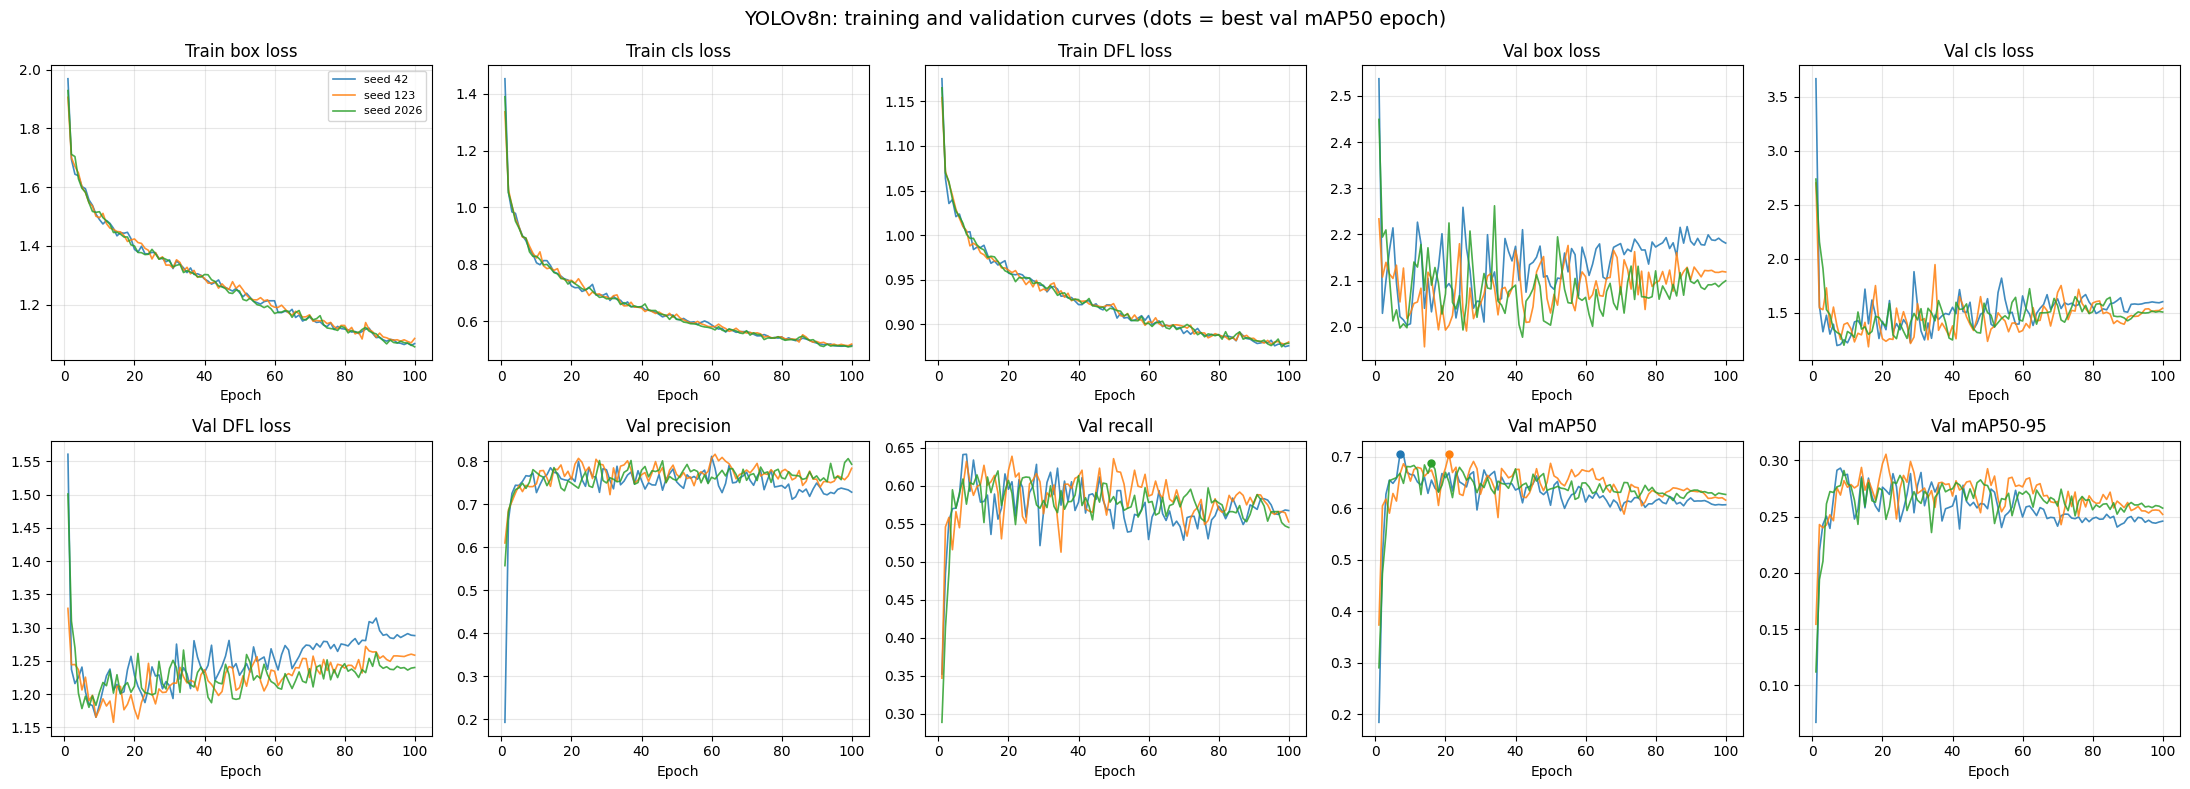

Saved: /kaggle/working/UAV_v2/reports/curves_YOLOv8n.png


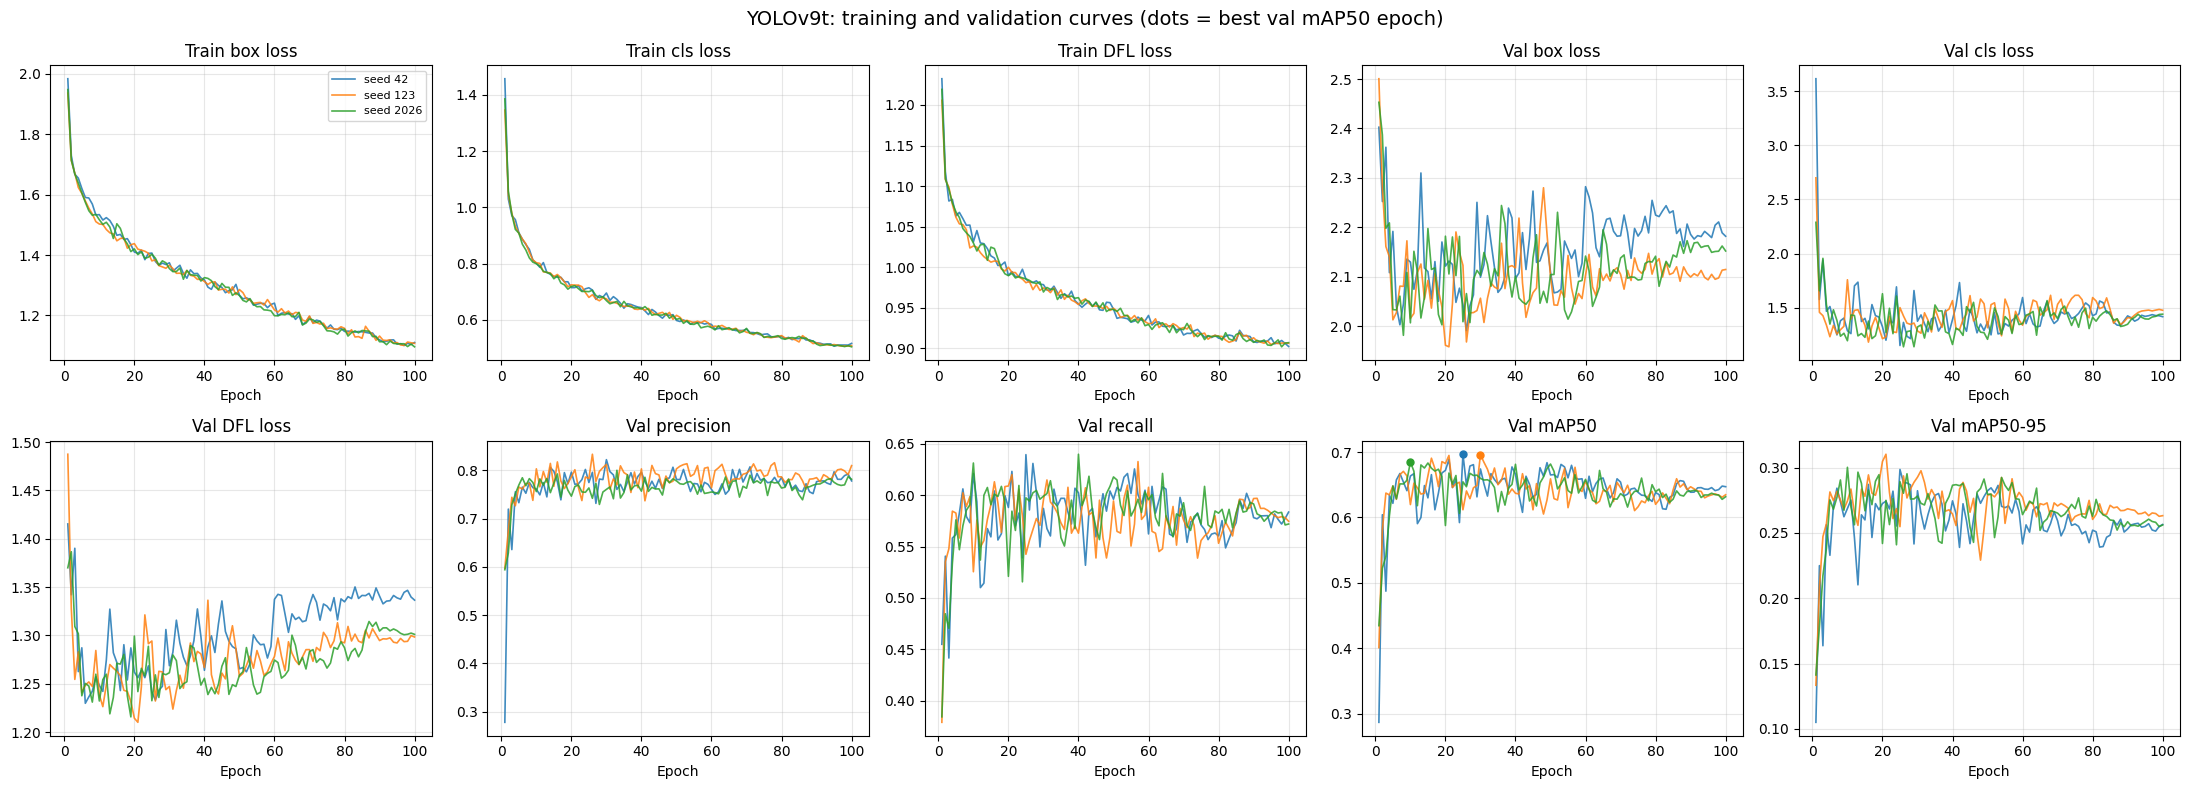

Saved: /kaggle/working/UAV_v2/reports/curves_YOLOv9t.png


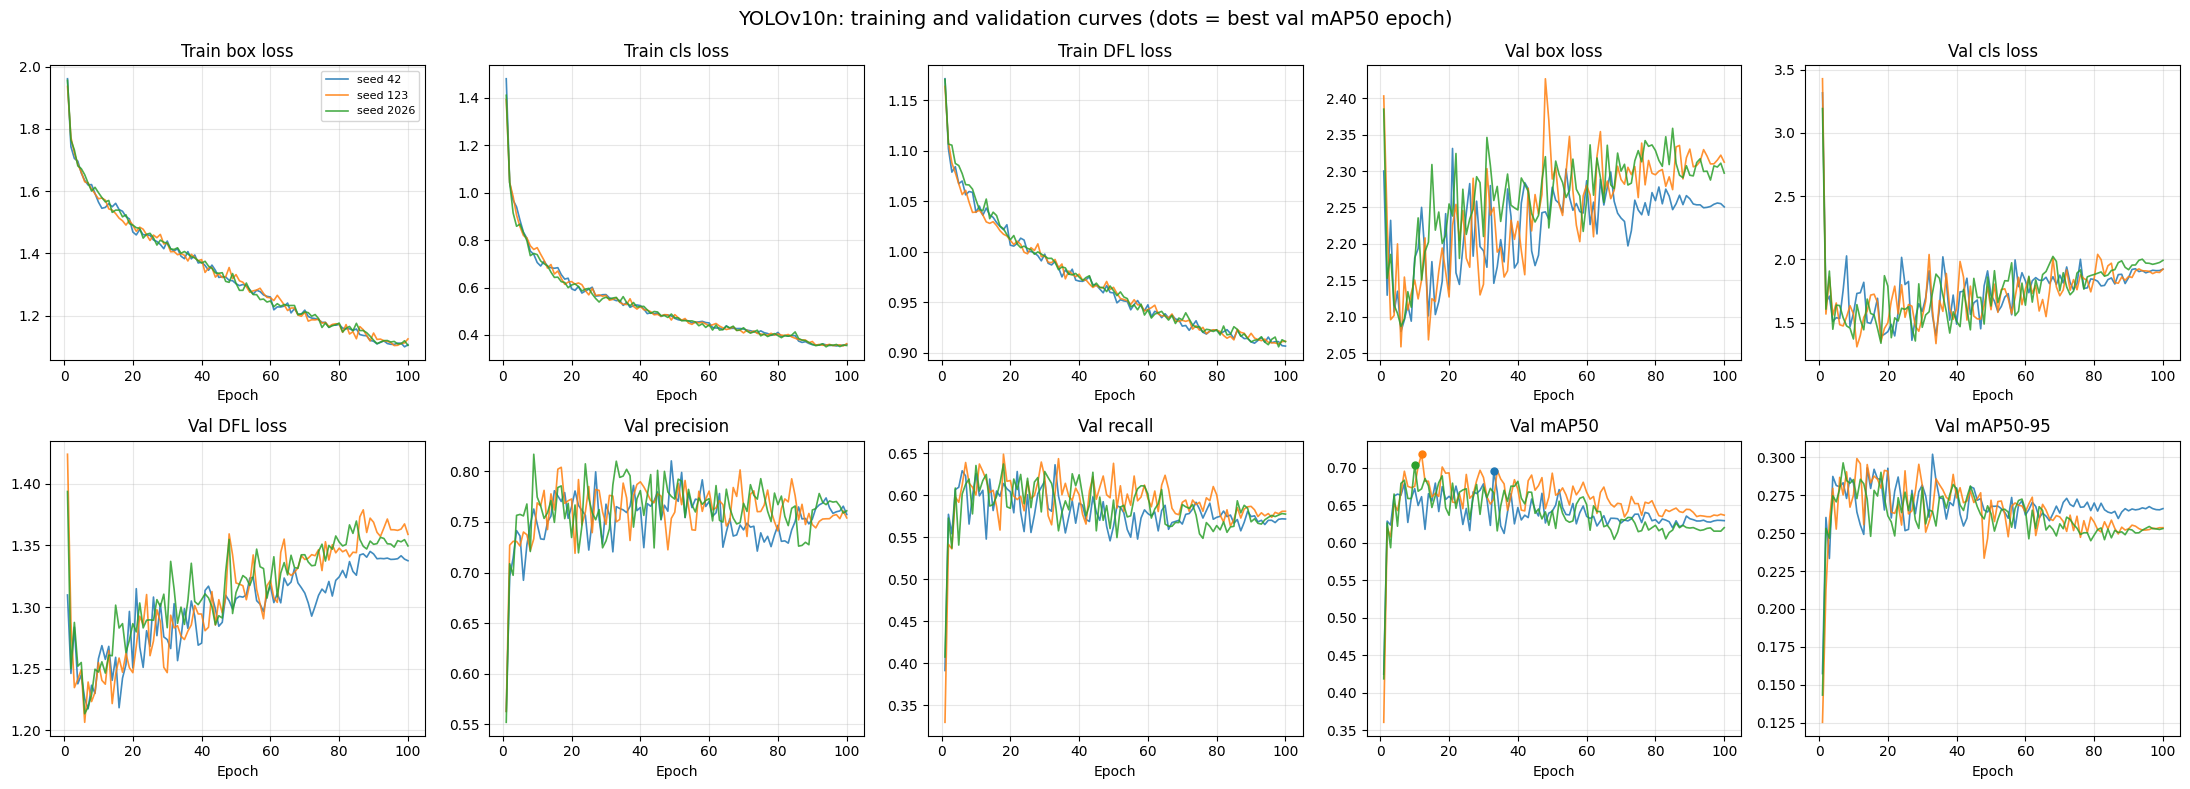

Saved: /kaggle/working/UAV_v2/reports/curves_YOLOv10n.png


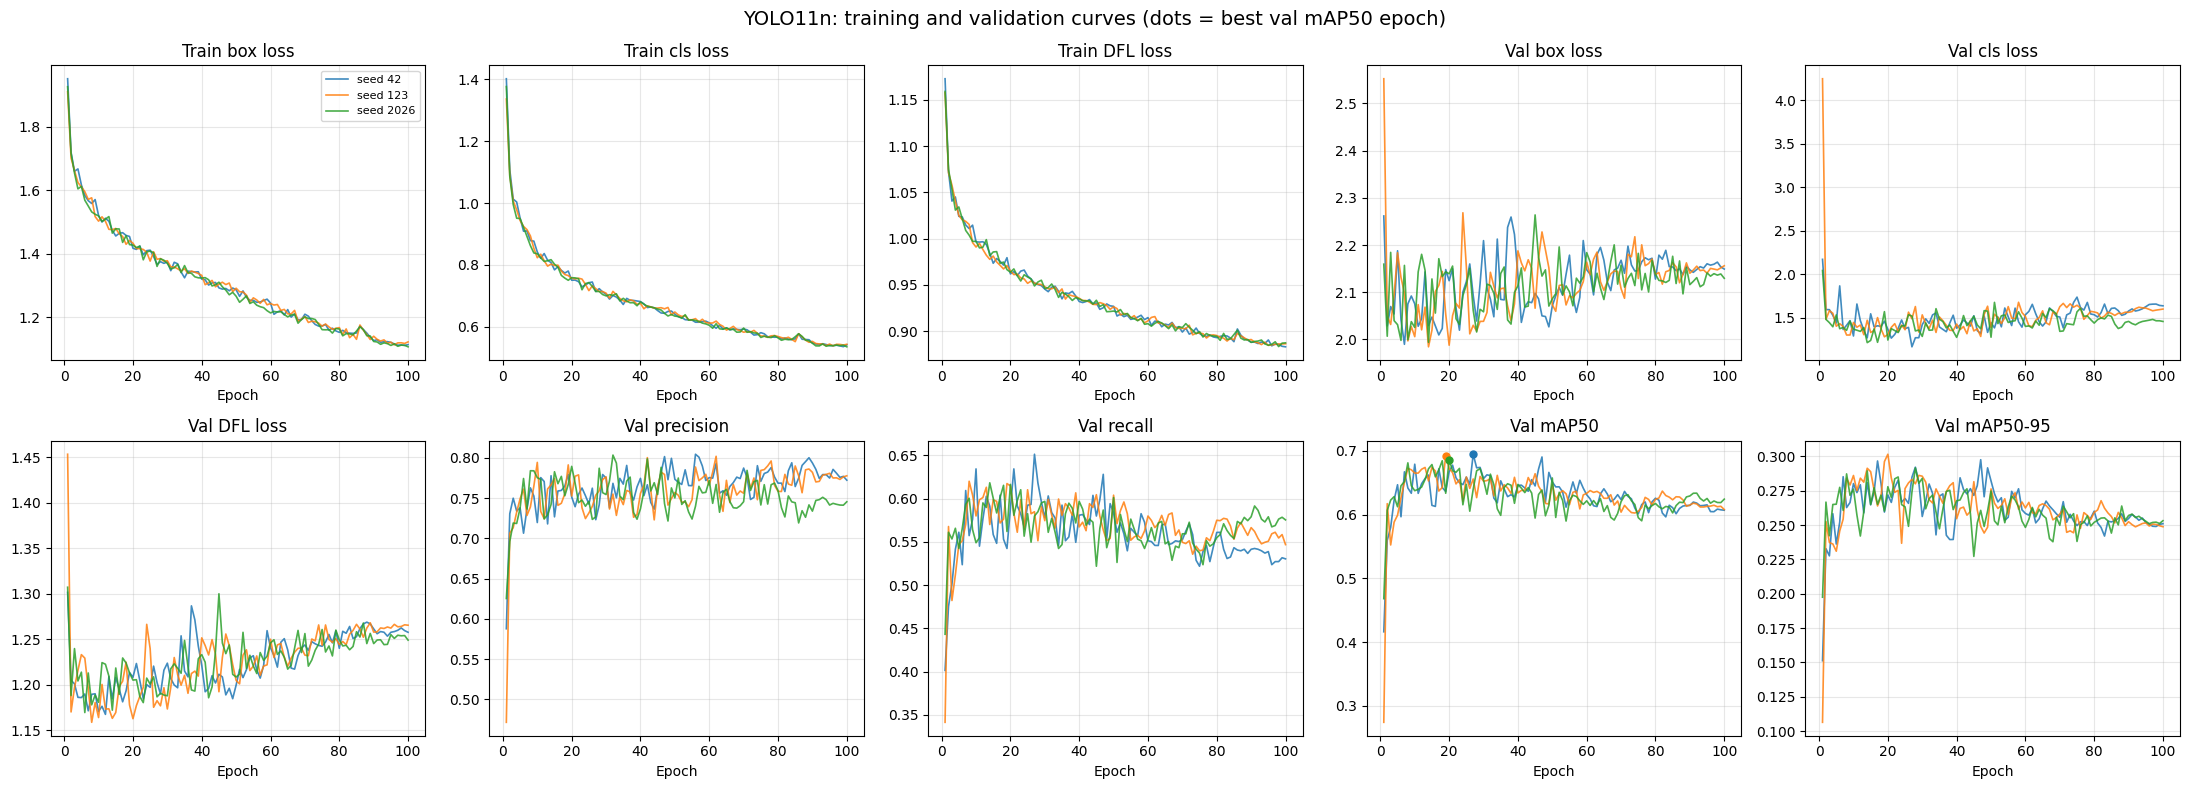

Saved: /kaggle/working/UAV_v2/reports/curves_YOLO11n.png

GENERATING MODEL COMPARISON


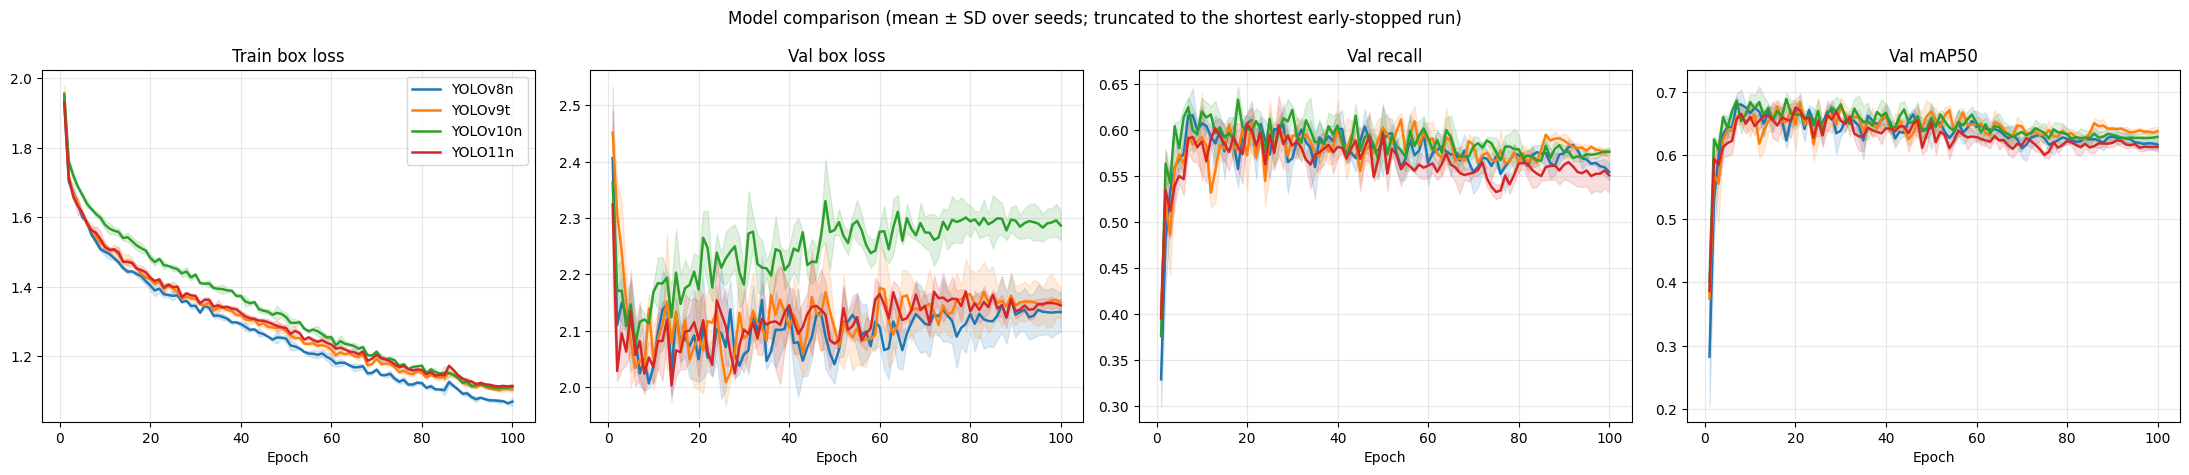

Saved: /kaggle/working/UAV_v2/reports/curves_model_comparison.png

GENERATING CONVERGENCE SUMMARY

Convergence summary:
   model  seed  epochs_run  best_epoch  best_val_mAP50  final_train_box  final_val_box
 YOLO11n    42         100          27          0.6946           1.1141         2.1490
 YOLO11n   123         100          19          0.6924           1.1226         2.1560
 YOLO11n  2026         100          20          0.6861           1.1072         2.1294
YOLOv10n    42         100          33          0.6956           1.1065         2.2508
YOLOv10n   123         100          12          0.7182           1.1253         2.3122
YOLOv10n  2026         100          10          0.7034           1.1046         2.2972
 YOLOv8n    42         100           7          0.7048           1.0676         2.1811
 YOLOv8n   123         100          21          0.7050           1.0852         2.1185
 YOLOv8n  2026         100          16          0.6883           1.0567         2.0994
 YOLOv9t  

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PATHS
# ============================================================

# READ-ONLY input: saved YOLO experiments
SRC = Path(
    "/kaggle/input/datasets/modigarinarendra/"
    "yolo-4-models-output-from-claide-code/UAV_v2"
)

YOLO_ROOT = SRC / "yolo_dataset"
RUNS      = SRC / "runs"

# WRITABLE output
OUT = Path("/kaggle/working/UAV_v2")
REP = OUT / "reports"
REP.mkdir(exist_ok=True, parents=True)

# ============================================================
# SETTINGS
# ============================================================

MODELS = ["YOLOv8n", "YOLOv9t", "YOLOv10n", "YOLO11n"]
SEEDS  = [42, 123, 2026]

COLORS = dict(
    zip(
        MODELS,
        ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    )
)

# ============================================================
# PATH CHECK
# ============================================================

print("============================================================")
print("PATH CHECK")
print("============================================================")
print("SRC       :", SRC)
print("YOLO_ROOT :", YOLO_ROOT)
print("RUNS      :", RUNS)
print("OUT       :", OUT)
print("REPORTS   :", REP)
print()

print("Available run directories:")
for p in sorted(RUNS.glob("*")):
    print(" ", p.name)

# ============================================================
# LOAD RESULTS.CSV
# ============================================================

def load(name, seed):

    f = RUNS / f"{name}_seed{seed}" / "results.csv"

    if not f.exists():
        print(f"WARNING: results.csv not found: {f}")
        return None

    df = pd.read_csv(f)

    # Remove whitespace from column names
    df.columns = [
        c.strip()
        for c in df.columns
    ]

    return df


# Load all available model/seed combinations
runs = {
    (m, s): load(m, s)
    for m in MODELS
    for s in SEEDS
}

# Keep only successfully loaded runs
runs = {
    k: v
    for k, v in runs.items()
    if v is not None
}

print("\n============================================================")
print("LOADED RUNS")
print("============================================================")

for (m, s), df in runs.items():

    print(
        f"{m:10s} | "
        f"seed={s:<4} | "
        f"epochs={len(df):<4}"
    )


# ============================================================
# COLUMN HELPER
# ============================================================

def col(df, prefix):
    """
    Tolerant to column-name differences across
    Ultralytics versions, e.g.:

        metrics/mAP50(B)
        metrics/mAP50
    """

    matches = [
        c
        for c in df.columns
        if c.startswith(prefix)
    ]

    if not matches:
        raise KeyError(
            f"No column found starting with '{prefix}'.\n"
            f"Available columns:\n{df.columns.tolist()}"
        )

    return matches[0]


# ============================================================
# MEAN CURVE OVER SEEDS
# ============================================================

def mean_curve(name, prefix):
    """
    Mean over seeds per epoch.

    Curves are truncated to the shortest available run
    because different runs may have different numbers of
    epochs due to early stopping.
    """

    series = [
        df[col(df, prefix)].to_numpy()
        for (m, s), df in runs.items()
        if m == name
    ]

    if not series:
        return None, None, None

    L = min(len(x) for x in series)

    A = np.vstack([
        x[:L]
        for x in series
    ])

    return (
        np.arange(1, L + 1),
        A.mean(0),
        A.std(0)
    )


# ============================================================
# FIGURE 1:
# PER-MODEL TRAINING AND VALIDATION CURVES
# ============================================================

PANELS = [
    ("train/box_loss",       "Train box loss"),
    ("train/cls_loss",       "Train cls loss"),
    ("train/dfl_loss",       "Train DFL loss"),

    ("val/box_loss",         "Val box loss"),
    ("val/cls_loss",         "Val cls loss"),
    ("val/dfl_loss",         "Val DFL loss"),

    ("metrics/precision",    "Val precision"),
    ("metrics/recall",       "Val recall"),

    ("metrics/mAP50(",       "Val mAP50"),
    ("metrics/mAP50-95",     "Val mAP50-95")
]

print("\n============================================================")
print("GENERATING PER-MODEL CURVES")
print("============================================================")

for name in MODELS:

    sub = {
        s: df
        for (m, s), df in runs.items()
        if m == name
    }

    if not sub:
        print(f"Skipping {name}: no results available.")
        continue

    fig, axes = plt.subplots(
        2,
        5,
        figsize=(22, 8)
    )

    axes = axes.ravel()

    for ax, (prefix, title) in zip(
        axes,
        PANELS
    ):

        for s, df in sub.items():

            c = col(df, prefix)

            ax.plot(
                df["epoch"],
                df[c],
                lw=1.2,
                alpha=0.85,
                label=f"seed {s}"
            )

            # Mark best validation mAP50 epoch
            if prefix.startswith("metrics/mAP50("):

                b = df[c].idxmax()

                ax.scatter(
                    df["epoch"][b],
                    df[c][b],
                    s=25,
                    zorder=3
                )

        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)

    axes[0].legend(fontsize=8)

    fig.suptitle(
        f"{name}: training and validation curves "
        "(dots = best val mAP50 epoch)",
        fontsize=14
    )

    plt.tight_layout()

    output_file = REP / f"curves_{name}.png"

    plt.savefig(
        output_file,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved: {output_file}")


# ============================================================
# FIGURE 2:
# MODEL COMPARISON — MEAN ± SD
# ============================================================

CMP = [
    ("train/box_loss",    "Train box loss"),
    ("val/box_loss",      "Val box loss"),
    ("metrics/recall",    "Val recall"),
    ("metrics/mAP50(",    "Val mAP50")
]

print("\n============================================================")
print("GENERATING MODEL COMPARISON")
print("============================================================")

fig, axes = plt.subplots(
    1,
    4,
    figsize=(22, 4.8)
)

for ax, (prefix, title) in zip(
    axes,
    CMP
):

    for name in MODELS:

        if not any(
            m == name
            for m, _ in runs
        ):
            continue

        x, mu, sd = mean_curve(
            name,
            prefix
        )

        if x is None:
            continue

        ax.plot(
            x,
            mu,
            color=COLORS[name],
            lw=1.8,
            label=name
        )

        ax.fill_between(
            x,
            mu - sd,
            mu + sd,
            color=COLORS[name],
            alpha=0.15
        )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)

axes[0].legend()

fig.suptitle(
    "Model comparison "
    "(mean ± SD over seeds; truncated to the shortest early-stopped run)"
)

plt.tight_layout()

comparison_file = (
    REP / "curves_model_comparison.png"
)

plt.savefig(
    comparison_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Saved: {comparison_file}")


# ============================================================
# CONVERGENCE SUMMARY TABLE
# ============================================================

print("\n============================================================")
print("GENERATING CONVERGENCE SUMMARY")
print("============================================================")

rows = []

for (m, s), df in runs.items():

    # Find mAP50 column
    c = col(
        df,
        "metrics/mAP50("
    )

    # Best validation mAP50 epoch
    b = df[c].idxmax()

    rows.append(
        dict(
            model=m,
            seed=s,
            epochs_run=len(df),
            best_epoch=int(
                df["epoch"][b]
            ),
            best_val_mAP50=df[c][b],

            final_train_box=df[
                col(
                    df,
                    "train/box_loss"
                )
            ].iloc[-1],

            final_val_box=df[
                col(
                    df,
                    "val/box_loss"
                )
            ].iloc[-1]
        )
    )


conv = (
    pd.DataFrame(rows)
    .sort_values(
        ["model", "seed"]
    )
    .reset_index(drop=True)
)

# Save convergence summary
conv_file = REP / "convergence_summary.csv"

conv.to_csv(
    conv_file,
    index=False
)

print("\nConvergence summary:")
print(
    conv.round(4).to_string(
        index=False
    )
)

print(f"\nSaved: {conv_file}")


# ============================================================
# FINAL OUTPUT FILE LIST
# ============================================================

print("\n============================================================")
print("GENERATED REPORT FILES")
print("============================================================")

for p in sorted(REP.glob("*")):

    print(
        f"{p.name:50s} "
        f"{p.stat().st_size / 1024:.1f} KB"
    )

print("\nCompleted successfully.")

In [5]:
from pathlib import Path
import yaml
from ultralytics import YOLO

# ============================================================
# PATHS
# ============================================================

SRC = Path(
    "/kaggle/input/datasets/modigarinarendra/"
    "yolo-4-models-output-from-claide-code/UAV_v2"
)

YOLO_ROOT = SRC / "yolo_dataset"
RUNS = SRC / "runs"

# Writable output directory
OUT = Path("/kaggle/working/UAV_v2")
OUT.mkdir(parents=True, exist_ok=True)

PR_OUT = OUT / "pr_curves"
PR_OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["YOLOv8n", "YOLOv9t", "YOLOv10n", "YOLO11n"]

SEED = 42
IMGSZ = 1280
CONF = 0.001

# ============================================================
# ORIGINAL DATA YAML
# ============================================================

ORIGINAL_YAML = YOLO_ROOT / "data.yaml"

if not ORIGINAL_YAML.exists():
    raise FileNotFoundError(
        f"Original data.yaml not found:\n{ORIGINAL_YAML}"
    )

print("Original YAML:")
print(ORIGINAL_YAML)

# ============================================================
# READ YAML
# ============================================================

with open(ORIGINAL_YAML, "r") as f:
    data = yaml.safe_load(f)

print("\nOriginal YAML contents:")
print(data)

# ============================================================
# FORCE ABSOLUTE DATASET PATH
# ============================================================

data["path"] = str(YOLO_ROOT)

# Keep the split folders relative to the absolute path above
data["train"] = "images/train"
data["val"]   = "images/val"
data["test"]  = "images/test"

# ============================================================
# CREATE CORRECTED YAML IN WORKING DIRECTORY
# ============================================================

FIXED_YAML = OUT / "data_fixed.yaml"

with open(FIXED_YAML, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("\nCorrected YAML:")
print(FIXED_YAML)

print("\nCorrected YAML contents:")
with open(FIXED_YAML, "r") as f:
    print(f.read())

# ============================================================
# VERIFY DATASET DIRECTORIES
# ============================================================

print("\nChecking dataset directories...")

for split in ["train", "val", "test"]:
    img_dir = YOLO_ROOT / "images" / split
    label_dir = YOLO_ROOT / "labels" / split

    print(f"\n{split.upper()}")
    print("Images :", img_dir)
    print("Labels :", label_dir)

    print("Images exists :", img_dir.exists())
    print("Labels exists :", label_dir.exists())

    if img_dir.exists():
        n_images = len(
            list(img_dir.glob("*"))
        )
        print("Image files   :", n_images)

    if label_dir.exists():
        n_labels = len(
            list(label_dir.glob("*.txt"))
        )
        print("Label files   :", n_labels)

# ============================================================
# GENERATE PR CURVES
# ============================================================

for name in MODELS:

    pt = (
        RUNS
        / f"{name}_seed{SEED}"
        / "weights"
        / "best.pt"
    )

    print("\n" + "=" * 70)
    print(f"{name} | seed={SEED}")
    print("Checkpoint:", pt)

    if not pt.exists():
        print("WARNING: checkpoint not found — skipping.")
        continue

    model = YOLO(str(pt))

    model.val(
        data=str(FIXED_YAML),
        split="test",
        imgsz=IMGSZ,
        conf=CONF,
        plots=True,
        project=str(PR_OUT),
        name=name,
        exist_ok=True,
        verbose=False
    )

    print(f"Completed: {name}")
    print(f"Results saved to: {PR_OUT / name}")

print("\n" + "=" * 70)
print("PR-curve generation completed.")
print("Output directory:", PR_OUT)

Original YAML:
/kaggle/input/datasets/modigarinarendra/yolo-4-models-output-from-claide-code/UAV_v2/yolo_dataset/data.yaml

Original YAML contents:
{'path': '/kaggle/working/UAV_v2/yolo_dataset', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'nc': 1, 'names': ['person']}

Corrected YAML:
/kaggle/working/UAV_v2/data_fixed.yaml

Corrected YAML contents:
path: /kaggle/input/datasets/modigarinarendra/yolo-4-models-output-from-claide-code/UAV_v2/yolo_dataset
train: images/train
val: images/val
test: images/test
nc: 1
names:
- person


Checking dataset directories...

TRAIN
Images : /kaggle/input/datasets/modigarinarendra/yolo-4-models-output-from-claide-code/UAV_v2/yolo_dataset/images/train
Labels : /kaggle/input/datasets/modigarinarendra/yolo-4-models-output-from-claide-code/UAV_v2/yolo_dataset/labels/train
Images exists : True
Labels exists : True
Image files   : 391
Label files   : 391

VAL
Images : /kaggle/input/datasets/modigarinarendra/yolo-4-models-output-from-